# <span style="color: #a855f7">Ensemble learning</span>

<span style="color: #a855f7">дерево рішень і важливість ознак, Random Forest та XGBoost для регресії, LogisticRegression і метрики класифікації на Breast Cancer</span>

In [1]:
from html import escape

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    r2_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.utils import Bunch
from xgboost import XGBRegressor

TEST_SIZE = 0.2
RANDOM_STATE = 42
COLORS = ["#a855f7", "#f472b6", "#60a5fa"]


def colorize(value, *, index=True):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        table = value.to_frame() if isinstance(value, pd.Series) else value
        html = table.to_html(border=0, index=index).replace(
            '<table ', '<table style="color: #a855f7; margin-left: 0; margin-right: auto; border-collapse: collapse" '
        )
        for tag in ("th", "td"):
            html = html.replace(
                f"<{tag}>",
                f'<{tag} style="padding: 6px 12px; border-bottom: 1px solid #746a80">',
            )
        display(HTML(html))
    else:
        display(HTML(f'<pre style="color: #a855f7; background: transparent">{escape(str(value))}</pre>'))


plt.style.use("dark_background")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "figure.facecolor": "#111116",
    "axes.facecolor": "#111116",
    "axes.edgecolor": "#746a80",
    "axes.labelcolor": "#e9d5ff",
    "axes.titlecolor": "#e9d5ff",
    "axes.titlesize": 13,
    "text.color": "#e9d5ff",
    "xtick.color": "#d8c8ed",
    "ytick.color": "#d8c8ed",
    "grid.color": "#746a80",
    "grid.alpha": 0.25,
    "font.size": 10,
})

## <span style="color: #a855f7">California Housing and regression split</span>

<span style="color: #a855f7">всі 8 ознак California Housing, 20640 спостережень, MedHouseVal вимірюється в одиницях 100000 USD, перший fetch потребує інтернету за відсутності кешу, один split 80/20 з random_state=42 використовується для всіх трьох регресорів</span>

In [2]:
data = fetch_california_housing(as_frame=True, return_X_y=False)
if not isinstance(data, Bunch) or not isinstance(data.frame, pd.DataFrame):
    raise TypeError("Expected a California Housing dataset with a pandas DataFrame")
features = [str(name) for name in data.feature_names]
required_columns = features + ["MedHouseVal"]
if not set(required_columns).issubset(data.frame.columns):
    raise ValueError("California Housing is missing required columns")
selected_data = data.frame[required_columns].copy()
if not np.isfinite(selected_data.to_numpy(dtype=float)).all():
    raise ValueError("Selected features and target must contain only finite numeric values")
X = selected_data[features].copy()
y = selected_data["MedHouseVal"].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE,
)
if not X_train.index.intersection(X_test.index).empty:
    raise ValueError("Regression train and test must not overlap")
colorize(f"Dataset rows: {len(X)} | selected features: {X.shape[1]}")
colorize("Selected features and target: first 5 rows")
colorize(selected_data.head())
colorize(pd.DataFrame({
    "split": ["train", "test"],
    "rows": [len(X_train), len(X_test)],
    "features": [X_train.shape[1], X_test.shape[1]],
}), index=False)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


split,rows,features
train,16512,8
test,4128,8


## <span style="color: #a855f7">Decision tree regression</span>

<span style="color: #a855f7">DecisionTreeRegressor(max_depth=5, random_state=42) навчається лише на train, R² оцінюється на test, ознаки не потребують масштабування для розбиттів дерева</span>

In [3]:
tree_model = DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE)
tree_model.fit(X_train, y_train)
tree_predictions = np.asarray(tree_model.predict(X_test), dtype=float)
tree_r2 = r2_score(y_test, tree_predictions)
colorize(pd.DataFrame({
    "model": ["DecisionTreeRegressor"],
    "max_depth": [tree_model.get_depth()],
    "leaves": [tree_model.get_n_leaves()],
    "test R²": [tree_r2],
}).round(4), index=False)

model,max_depth,leaves,test R²
DecisionTreeRegressor,5,32,0.5997


## <span style="color: #a855f7">Decision tree feature importance</span>

<span style="color: #a855f7">feature_importances_ показує нормоване сумарне зменшення MSE на train, сума дорівнює 1, діаграма відсортована для читабельності, це оцінка важливості всередині конкретного дерева, а не доказ причинності, взаємопов'язані ознаки можуть розподіляти важливість між собою</span>

feature,importance
MedInc,0.7712
AveOccup,0.1284
HouseAge,0.0416
AveRooms,0.0313
Latitude,0.0220
Population,0.0025
Longitude,0.0021
AveBedrms,0.0009


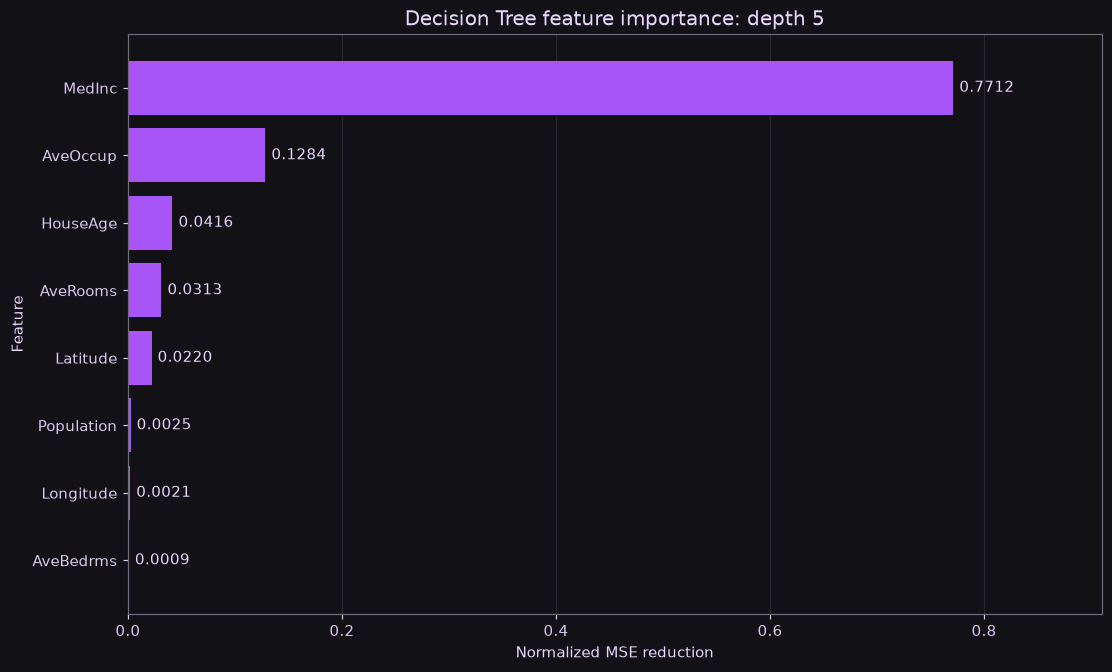

In [4]:
feature_importance = pd.DataFrame({
    "feature": features,
    "importance": np.asarray(tree_model.feature_importances_, dtype=float),
}).sort_values("importance", ascending=False).reset_index(drop=True)
colorize(feature_importance.round(4), index=False)
importance_plot = feature_importance.sort_values("importance")
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
importance_bars = ax.barh(importance_plot["feature"].tolist(), importance_plot["importance"].to_numpy(), color=COLORS[0])
ax.bar_label(importance_bars, fmt="%.4f", padding=4)
ax.set(title="Decision Tree feature importance: depth 5", xlabel="Normalized MSE reduction", ylabel="Feature")
ax.set_xlim(0, max(float(feature_importance["importance"].max()) * 1.18, 0.1))
ax.grid(axis="x")
ax.set_axisbelow(True)
plt.show()

## <span style="color: #a855f7">Decision tree vs random forest</span>

<span style="color: #a855f7">RandomForestRegressor(n_estimators=100, random_state=42), дані, ознаки й test ті самі, навчене дерево використовується повторно, n_jobs=-1 дозволяє паралельне навчання дерев</span>

In [5]:
forest_model = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
forest_model.fit(X_train, y_train)
forest_predictions = np.asarray(forest_model.predict(X_test), dtype=float)
forest_r2 = r2_score(y_test, forest_predictions)
tree_forest_comparison = pd.DataFrame({
    "model": ["DecisionTreeRegressor", "RandomForestRegressor"],
    "test R²": [tree_r2, forest_r2],
})
colorize(tree_forest_comparison.round(4), index=False)
colorize(f"Random Forest minus Decision Tree test R²: {forest_r2 - tree_r2:+.4f}")

model,test R²
DecisionTreeRegressor,0.5997
RandomForestRegressor,0.8046


## <span style="color: #a855f7">XGBoost and model comparison</span>

<span style="color: #a855f7">XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42), test не використовується для early stopping чи підбору параметрів, результати порівнюються за R² на одному test</span>

model,test R²
DecisionTreeRegressor,0.5997
RandomForestRegressor,0.8046
XGBRegressor,0.8339


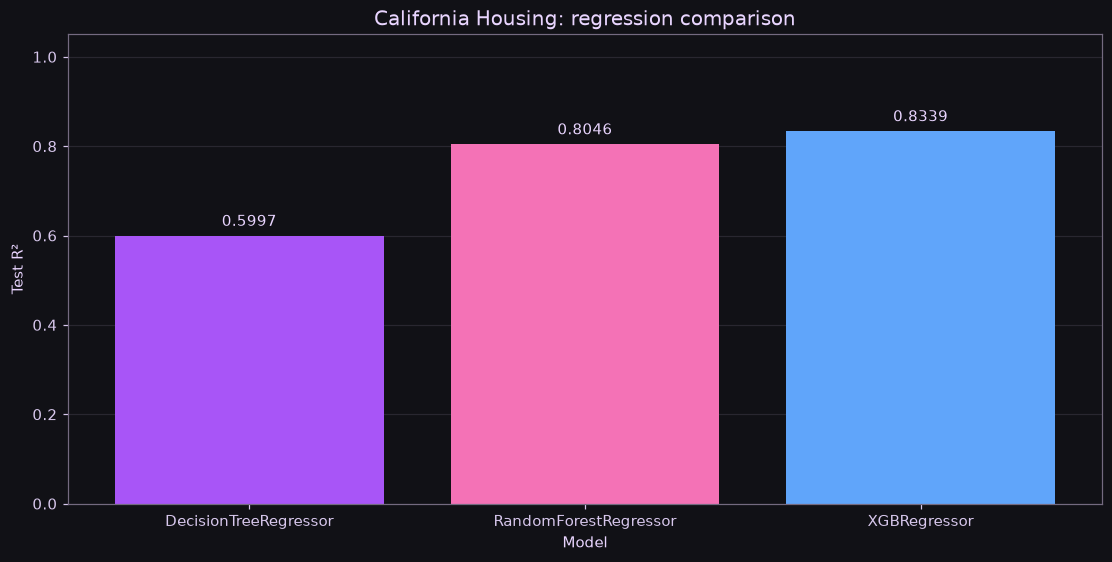

In [6]:
xgb_model = XGBRegressor(
    n_estimators=200, learning_rate=0.1, max_depth=5, random_state=RANDOM_STATE,
    n_jobs=4,
)
xgb_model.fit(X_train, y_train)
xgb_predictions = np.asarray(xgb_model.predict(X_test), dtype=float)
xgb_r2 = r2_score(y_test, xgb_predictions)
regression_comparison = pd.DataFrame({
    "model": ["DecisionTreeRegressor", "RandomForestRegressor", "XGBRegressor"],
    "test R²": [tree_r2, forest_r2, xgb_r2],
})
colorize(regression_comparison.round(4), index=False)
colorize(f"XGBoost minus Random Forest test R²: {xgb_r2 - forest_r2:+.4f}")
best_regressor = regression_comparison.loc[regression_comparison["test R²"].idxmax(), "model"]
colorize(f"Highest R² on this test split: {best_regressor}")
fig, ax = plt.subplots(layout="constrained")
bars = ax.bar(regression_comparison["model"].tolist(), regression_comparison["test R²"].to_numpy(), color=COLORS)
ax.bar_label(bars, fmt="%.4f", padding=4)
ax.set(title="California Housing: regression comparison", xlabel="Model", ylabel="Test R²", ylim=(min(0, regression_comparison["test R²"].min() - 0.05), 1.05))
ax.grid(axis="y")
ax.set_axisbelow(True)
plt.show()

<span style="color: #a855f7">модель з найвищим test R² вказана над графіком, вищий R² означає меншу суму квадратів помилок на цій test-вибірці, висновок стосується цього split і заданих параметрів, R² не є відсотком точно вгаданих цін</span>

## <span style="color: #a855f7">Breast Cancer and classification split</span>

<span style="color: #a855f7">load_breast_cancer містить 569 зразків і 30 числових ознак, дані входять до scikit-learn і не потребують окремого завантаження, початкові мітки збережені: 0 - malignant, 1 - benign, split 80/20 з random_state=42</span>

In [7]:
cancer_data = load_breast_cancer(as_frame=True, return_X_y=False)
if not isinstance(cancer_data, Bunch) or not isinstance(cancer_data.frame, pd.DataFrame):
    raise TypeError("Expected a Breast Cancer dataset with a pandas DataFrame")
cancer_features = [str(name) for name in cancer_data.feature_names]
cancer_X = cancer_data.frame[cancer_features].copy()
cancer_y = cancer_data.frame["target"].astype(int)
if not np.isfinite(cancer_X.to_numpy(dtype=float)).all() or set(cancer_y.unique()) != {0, 1}:
    raise ValueError("Breast Cancer requires finite features and both binary classes")
X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    cancer_X, cancer_y, test_size=TEST_SIZE, random_state=RANDOM_STATE,
)
if not X_class_train.index.intersection(X_class_test.index).empty:
    raise ValueError("Classification train and test must not overlap")
class_distribution = pd.DataFrame({
    "class": [0, 1],
    "label": ["malignant", "benign"],
    "all rows": cancer_y.value_counts().reindex([0, 1], fill_value=0).to_numpy(),
    "train rows": y_class_train.value_counts().reindex([0, 1], fill_value=0).to_numpy(),
    "test rows": y_class_test.value_counts().reindex([0, 1], fill_value=0).to_numpy(),
})
colorize(f"Breast Cancer rows: {len(cancer_X)} | features: {cancer_X.shape[1]} | train: {len(X_class_train)} | test: {len(X_class_test)}")
colorize(class_distribution, index=False)
colorize("First 5 rows, first 5 features: all 30 features are used for classification")
colorize(cancer_X.iloc[:5, :5])

class,label,all rows,train rows,test rows
0,malignant,212,169,43
1,benign,357,286,71


,mean radius,mean texture,mean perimeter,mean area,mean smoothness
0,17.99,10.38,122.80,1001.0,0.11840
1,20.57,17.77,132.90,1326.0,0.08474
2,19.69,21.25,130.00,1203.0,0.10960
3,11.42,20.38,77.58,386.1,0.14250
4,20.29,14.34,135.10,1297.0,0.10030


## <span style="color: #a855f7">Logistic regression metrics</span>

<span style="color: #a855f7">Pipeline зі StandardScaler і LogisticRegression(max_iter=1000), scaler навчається лише на classification train, Precision, Recall і F1 нижче рахуються для позитивного класу 1 = benign, Accuracy враховує обидва класи</span>

In [8]:
classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000)),
])
classifier.fit(X_class_train, y_class_train)
class_predictions = np.asarray(classifier.predict(X_class_test), dtype=int)
classification_metrics = pd.DataFrame({
    "metric": ["Accuracy", "Precision", "Recall", "F1"],
    "value": [
        accuracy_score(y_class_test, class_predictions),
        precision_score(y_class_test, class_predictions, pos_label=1, zero_division=0),
        recall_score(y_class_test, class_predictions, pos_label=1, zero_division=0),
        f1_score(y_class_test, class_predictions, pos_label=1, zero_division=0),
    ],
})
colorize(classification_metrics.round(4), index=False)
np.testing.assert_allclose(classifier.named_steps["scaler"].mean_, X_class_train.mean().to_numpy())
colorize(f"Logistic regression iterations: {int(classifier.named_steps['model'].n_iter_[0])} / 1000")

metric,value
Accuracy,0.9737
Precision,0.9722
Recall,0.9859
F1,0.9790


## <span style="color: #a855f7">Confusion matrix</span>

<span style="color: #a855f7">рядки - реальні класи, стовпці - передбачені, TN: malignant передбачено як malignant, TP: benign передбачено як benign, FP: malignant помилково передбачено як benign, FN: benign помилково передбачено як malignant, позначення залежать від позитивного класу 1</span>

,Predicted malignant (0),Predicted benign (1)
Actual malignant (0),41,2
Actual benign (1),1,70


outcome,count
TN,41
FP,2
FN,1
TP,70


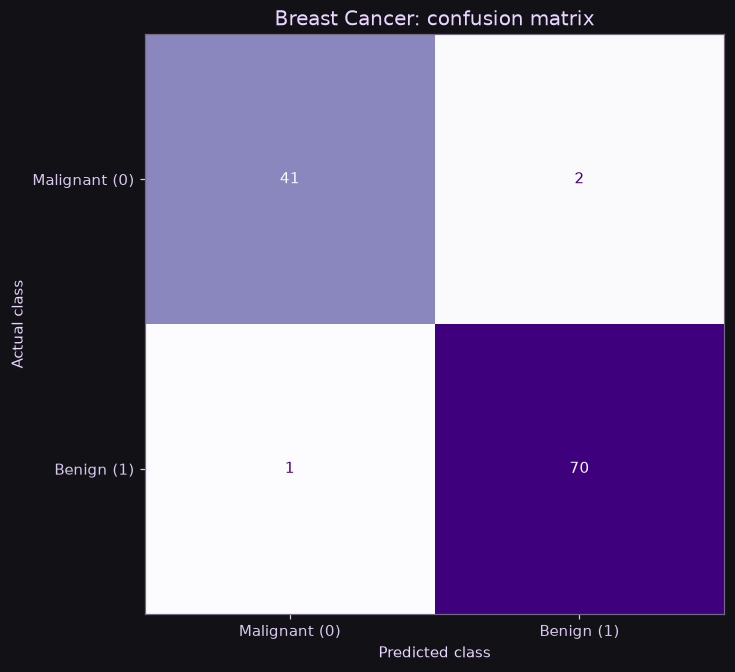

In [9]:
cm = confusion_matrix(y_class_test, class_predictions, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
colorize(pd.DataFrame(cm, index=["Actual malignant (0)", "Actual benign (1)"], columns=["Predicted malignant (0)", "Predicted benign (1)"]))
colorize(pd.DataFrame({
    "outcome": ["TN", "FP", "FN", "TP"],
    "count": [tn, fp, fn, tp],
}), index=False)
fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant (0)", "Benign (1)"],
)
display_matrix.plot(ax=ax, cmap="Purples", values_format="d", colorbar=False)
ax.set(title="Breast Cancer: confusion matrix", xlabel="Predicted class", ylabel="Actual class")
plt.show()

<span style="color: #a855f7">всі метрики та confusion matrix обчислені з тих самих test-прогнозів, правильне читання Precision і Recall потребує врахування позначення класу 1, зразки test не використовувалися для fit scaler чи навчання LogisticRegression</span>